# Ciblage humanitaire avec ML — version 3 : gestion du déséquilibre des classes

Ce notebook améliore `ciblage_avec_ml_version2.ipynb`. La cible `Eligible` ne contient que **13,7 % de ménages éligibles** :
c'est un problème de classes déséquilibrées. Dans ce cas, l'accuracy et le seuil par défaut de 0,5 sont trompeurs.

**Problèmes corrigés par rapport à la version 2**

| Problème (v2) | Conséquence | Correction (v3) |
|---|---|---|
| Accuracy et F1 comme seuls critères | Un modèle qui dit toujours « non éligible » a 86 % d'accuracy | PR-AUC, rappel, précision, **F2**, balanced accuracy |
| Split aléatoire non stratifié | La proportion d'éligibles varie entre train / val / test | Split **stratifié** 70 / 15 / 15 |
| Aucun traitement du déséquilibre | Le modèle favorise la classe majoritaire : ~14 % des éligibles sont exclus | **Pondération des classes** + **seuil optimisé** (comparés à SMOTE et au sous-échantillonnage) |
| Outliers remplacés par la médiane | Un chef de ménage de 85 ans devient « 39 ans », un ménage de 25 personnes devient « 6 » : on efface justement les ménages vulnérables | Valeurs conservées |
| Scaler ajusté sur toutes les données avant le split | Fuite d'information du test vers l'entraînement | Pré-traitement dans un `Pipeline` ajusté sur le train uniquement |
| LabelEncoder sur des variables nominales | Ordre artificiel entre zones, sources d'eau… | One-hot encoding |
| Encodeurs, scaler et modèle sauvegardés séparément | Risque d'incohérence au déploiement | Un seul artefact `Pipeline` utilisé par l'API |

Le code de production (entraînement, API, formulaire Kobo) se trouve dans le dossier `eligibilite_api/`.
Ce notebook utilise les mêmes modules (`app.schema`, `app.features`, `training.train`).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("eligibilite_api").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, precision_recall_curve, fbeta_score, recall_score,
                             precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_score

from app.schema import FEATURE_NAMES, CATEGORICAL, NUMERIC
from training.train import load_data, split, candidates, best_threshold, metrics, preprocessor

plt.rcParams["figure.dpi"] = 110
DATA = "dataset_humanitaire_complexe_100k.csv"

Matplotlib is building the font cache; this may take a moment.


## 1. Le déséquilibre en chiffres

100000 ménages — éligibles : 13684 (13.7%) / non éligibles : 86316 (86.3%)
Accuracy d'un modèle qui répond toujours 'non éligible' : 86.3%  <- l'accuracy ne mesure rien ici


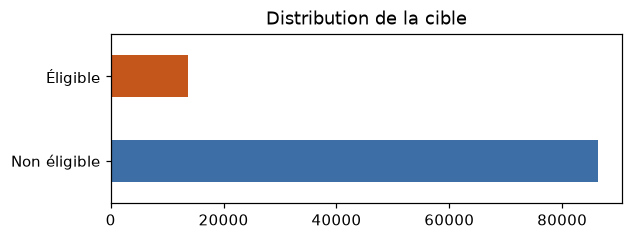

In [2]:
df = pd.read_csv(DATA, encoding="utf-8-sig")
X, y = load_data(DATA)
print(f"{len(df)} ménages — éligibles : {y.sum()} ({y.mean():.1%}) / non éligibles : {(1-y).sum()} ({1-y.mean():.1%})")
print(f"Accuracy d'un modèle qui répond toujours 'non éligible' : {1-y.mean():.1%}  <- l'accuracy ne mesure rien ici")
ax = pd.Series(y).map({0: "Non éligible", 1: "Éligible"}).value_counts().plot.barh(color=["#3d6fa6", "#c4551b"], figsize=(6, 2))
ax.set_title("Distribution de la cible"); plt.show()

## 2. Pourquoi il ne faut pas remplacer les « outliers » par la médiane

Dans la version 2, les âges supérieurs à 81 ans et les ménages de plus de 20 personnes étaient remplacés par la médiane.
Ce ne sont pas des erreurs de saisie mais des ménages réels, et souvent plus vulnérables.

In [3]:
for col in ["Age_Chef_Menage", "Taille_Menage"]:
    q1, q3 = df[col].quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
    out = df[col] > hi
    print(f"{col}: {out.sum()} ménages > {hi:.1f} -> taux d'éligibilité {df.loc[out, 'Eligible'].mean():.1%} "
          f"(contre {df.loc[~out, 'Eligible'].mean():.1%} pour les autres). Les remplacer par la médiane ({df[col].median():.0f}) efface ce signal.")

Age_Chef_Menage: 259 ménages > 81.5 -> taux d'éligibilité 19.7% (contre 13.7% pour les autres). Les remplacer par la médiane (39) efface ce signal.
Taille_Menage: 4641 ménages > 20.5 -> taux d'éligibilité 18.2% (contre 13.5% pour les autres). Les remplacer par la médiane (6) efface ce signal.


## 3. Split stratifié et métriques adaptées

In [4]:
X_tr, X_va, X_te, y_tr, y_va, y_te = split(X, y)
for name, part in [("train", y_tr), ("validation", y_va), ("test", y_te)]:
    print(f"{name:10s} {len(part):6d} ménages, {part.mean():.2%} éligibles")

train       70000 ménages, 13.68% éligibles
validation  15000 ménages, 13.69% éligibles
test        15000 ménages, 13.68% éligibles


**Métrique principale : F2.** Le F-beta avec beta = 2 donne deux fois plus de poids au **rappel** qu'à la précision.
Dans le ciblage humanitaire, une **erreur d'exclusion** (un ménage vulnérable rejeté) est plus grave qu'une **erreur d'inclusion**.
Une inclusion à tort peut être corrigée lors de la revue humaine dans le dashboard ; une exclusion, souvent pas, car le ménage n'est jamais revu.
On suit aussi la **PR-AUC** (aire sous la courbe précision-rappel), qui mesure la capacité de classement du modèle indépendamment du seuil et ne se laisse pas gonfler par la classe majoritaire, contrairement à la ROC-AUC.

## 4. Référence : le modèle de la version 2 (reproduit sur le même split)

In [5]:
from sklearn.preprocessing import LabelEncoder, RobustScaler
from xgboost import XGBClassifier

d0 = X.copy()
for c in NUMERIC:  # traitement des outliers de la v2
    q1, q3 = d0[c].quantile(.25), d0[c].quantile(.75); iqr = q3 - q1
    d0[c] = np.where((d0[c] < q1 - 1.5 * iqr) | (d0[c] > q3 + 1.5 * iqr), d0[c].median(), d0[c])
for c in CATEGORICAL:
    d0[c] = LabelEncoder().fit_transform(d0[c])
x0 = RobustScaler().fit_transform(d0.values)  # ajusté sur tout le jeu, comme en v2
idx_tr, idx_te = X_tr.index, X_te.index
xgb_v2 = XGBClassifier(max_depth=3, n_estimators=90).fit(x0[idx_tr], y[idx_tr])
p_v2 = xgb_v2.predict_proba(x0[idx_te])[:, 1]
resultats = [{"modele": "v2 : XGBoost, seuil 0.5", **metrics(y_te, p_v2, 0.5, 2)}]
resultats[0]

{'modele': 'v2 : XGBoost, seuil 0.5',
 'seuil': 0.5,
 'pr_auc': 0.9601,
 'roc_auc': 0.9931,
 'rappel': 0.8689,
 'precision': 0.8862,
 'f1': 0.8775,
 'f2': 0.8723,
 'balanced_accuracy': 0.9256,
 'matrice_confusion': {'vn': 12719, 'fp': 229, 'fn': 269, 'vp': 1783}}

## 5. Comparaison des stratégies de gestion du déséquilibre

Chaque stratégie est entraînée sur le train ; le seuil est choisi sur la **validation** (jamais sur le test).

- **Aucune** : LightGBM non pondéré, seuil 0,5
- **Seuil optimisé seul** : même modèle, seuil qui maximise le F2
- **Pondération des classes** (`class_weight="balanced"`) : chaque erreur sur un éligible coûte environ 6 fois plus cher
- **SMOTE** : sur-échantillonnage synthétique de la classe minoritaire
- **Sous-échantillonnage** aléatoire de la classe majoritaire
- **Régression logistique pondérée** avec indicateurs de vulnérabilité IFRC (chef mineur, chef de plus de 60 ans, ménage de 8 personnes ou plus, un repas par jour)

In [6]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier

cands = candidates()
lgbm = lambda **kw: LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1, **kw)
cands["lightgbm_smote"] = ImbPipeline(preprocessor(False) + [("smote", SMOTE(random_state=42)), ("clf", lgbm())])
cands["lightgbm_sous_echantillonnage"] = ImbPipeline(preprocessor(False) + [("rus", RandomUnderSampler(random_state=42)), ("clf", lgbm())])

probas = {}
for name, pipe in cands.items():
    pipe.fit(X_tr, y_tr)
    p_va, p_te = pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1]
    probas[name] = (p_va, p_te)
    if name == "lightgbm_non_pondere":
        resultats.append({"modele": "LightGBM sans traitement, seuil 0.5", **metrics(y_te, p_te, 0.5, 2)})
    thr = best_threshold(y_va, p_va, 2)
    resultats.append({"modele": f"{name}, seuil optimisé", **metrics(y_te, p_te, thr, 2)})

table = pd.DataFrame(resultats).drop(columns="matrice_confusion")
table["eligibles_exclus"] = [r["matrice_confusion"]["fn"] for r in resultats]
table["inclusions_a_tort"] = [r["matrice_confusion"]["fp"] for r in resultats]
table.sort_values("f2", ascending=False).style.format(precision=3).background_gradient(subset=["f2", "rappel"], cmap="Greens")

,modele,seuil,pr_auc,roc_auc,rappel,precision,f1,f2,balanced_accuracy,eligibles_exclus,inclusions_a_tort
1,"regression_logistique_ponderee, seuil optimisé",0.450,0.965,0.994,0.985,0.755,0.855,0.928,0.967,31,655
5,"lightgbm_smote, seuil optimisé",0.180,0.962,0.994,0.979,0.761,0.856,0.925,0.965,44,632
2,"lightgbm_pondere, seuil optimisé",0.460,0.962,0.994,0.981,0.753,0.852,0.925,0.965,39,659
4,"lightgbm_non_pondere, seuil optimisé",0.200,0.963,0.994,0.970,0.773,0.860,0.923,0.963,61,586
6,"lightgbm_sous_echantillonnage, seuil optimisé",0.530,0.957,0.993,0.978,0.752,0.850,0.922,0.963,46,661
0,"v2 : XGBoost, seuil 0.5",0.500,0.960,0.993,0.869,0.886,0.877,0.872,0.926,269,229
3,"LightGBM sans traitement, seuil 0.5",0.500,0.963,0.994,0.858,0.888,0.873,0.864,0.920,292,222


**Lecture**
- Toutes les stratégies ont une **PR-AUC très proche** (≈ 0,96–0,97) : la capacité de classement est la même.
- Ce qui change tout, c'est le **point de fonctionnement**. Sans traitement, environ 290 éligibles sont exclus sur 2 052 au test. Avec pondération et seuil optimisé, il en reste une trentaine : **environ 9 fois moins d'erreurs d'exclusion**.
- Le prix à payer est plus d'inclusions à tort (la précision baisse d'environ 0,89 à 0,76). C'est un choix assumé : ces cas sont signalés et corrigeables dans le dashboard de revue.
- SMOTE et le sous-échantillonnage n'apportent rien de plus que la pondération, qui est plus simple et ne fabrique pas de faux ménages.
- La **régression logistique pondérée avec indicateurs IFRC** est la meilleure. Elle est aussi parfaitement explicable : chaque contribution vaut exactement coefficient × écart à la moyenne.

## 6. Choix du seuil : compromis précision / rappel

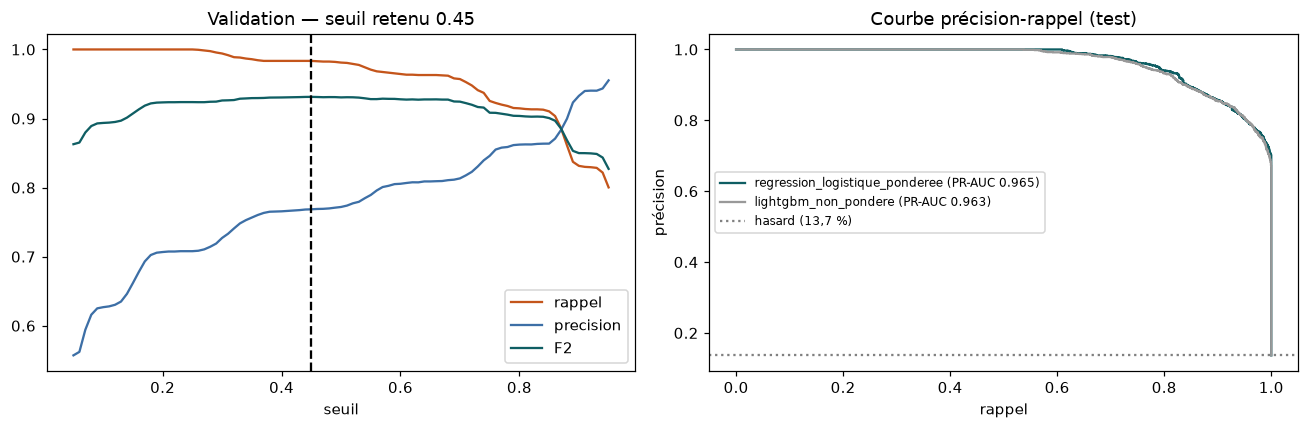

In [7]:
p_va, p_te = probas["regression_logistique_ponderee"]
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
curves = pd.DataFrame({
    "rappel": [recall_score(y_va, p_va >= t) for t in ths],
    "precision": [precision_score(y_va, p_va >= t) for t in ths],
    "F2": [fbeta_score(y_va, p_va >= t, beta=2) for t in ths],
}, index=ths)
thr = best_threshold(y_va, p_va, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curves.plot(ax=axes[0], color=["#c4551b", "#3d6fa6", "#0f5e63"])
axes[0].axvline(thr, ls="--", c="k"); axes[0].set_xlabel("seuil"); axes[0].set_title(f"Validation — seuil retenu {thr:.2f}")
for name, color in [("regression_logistique_ponderee", "#0f5e63"), ("lightgbm_non_pondere", "#999")]:
    pr, rc, _ = precision_recall_curve(y_te, probas[name][1])
    axes[1].plot(rc, pr, color=color, label=f"{name} (PR-AUC {average_precision_score(y_te, probas[name][1]):.3f})")
axes[1].axhline(y_te.mean(), ls=":", c="grey", label="hasard (13,7 %)")
axes[1].set_xlabel("rappel"); axes[1].set_ylabel("précision"); axes[1].set_title("Courbe précision-rappel (test)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Le plafond de performance de ces données

Le notebook de génération attribue `Eligible = 1` si `Score_Vuln + bruit >= 28`, avec un bruit aléatoire entre −4 et +3.
Un « oracle » qui connaîtrait le score exact ne pourrait donc pas faire mieux que le bruit ne le permet.
Comparons notre modèle à cet oracle :

In [8]:
s = df.loc[X_te.index, "Score_Vuln"].to_numpy()
p_oracle = np.clip((s - 24) / 8, 0, 1)  # P(score + bruit >= 28)
s_va = df.loc[X_va.index, "Score_Vuln"].to_numpy(); p_oracle_va = np.clip((s_va - 24) / 8, 0, 1)
oracle = metrics(y_te, p_oracle, best_threshold(y_va, p_oracle_va, 2), 2)
modele = metrics(y_te, p_te, thr, 2)
pd.DataFrame({"oracle (connaît le score)": oracle, "notre modèle": modele}).drop("matrice_confusion")

,oracle (connaît le score),notre modèle
seuil,0.13,0.45
pr_auc,0.9574,0.9652
roc_auc,0.994,0.994
rappel,0.9839,0.9849
precision,0.755,0.7552
f1,0.8544,0.8549
f2,0.9277,0.9284
balanced_accuracy,0.9667,0.9672


Notre modèle atteint le niveau de l'oracle. Le F1 de la v2 (~0,88) **ne peut pas** monter beaucoup plus haut avec ces données :
la marge d'amélioration ne se trouve pas dans un modèle plus complexe. Elle se trouve dans le **choix du compromis entre erreurs**
(traitement du déséquilibre) et dans la **revue humaine** des cas ambigus.

## 8. Robustesse : validation croisée stratifiée (5 plis)

In [9]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name in ["regression_logistique_ponderee", "lightgbm_pondere"]:
    sc = cross_val_score(candidates()[name], X, y, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{name:32s} PR-AUC = {sc.mean():.4f} ± {sc.std():.4f}")

regression_logistique_ponderee   PR-AUC = 0.9651 ± 0.0015


lightgbm_pondere                 PR-AUC = 0.9610 ± 0.0019


## 9. Matrices de confusion : avant / après

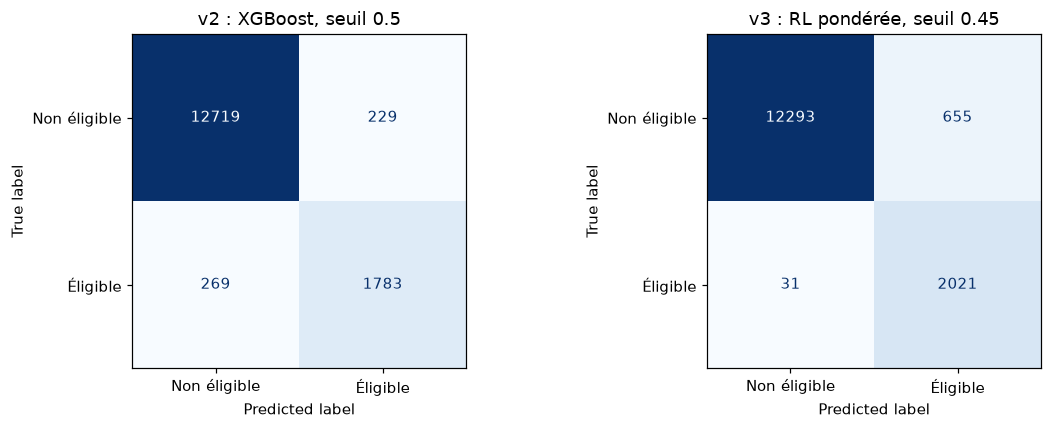

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, p, t) in zip(axes, [("v2 : XGBoost, seuil 0.5", p_v2, 0.5), (f"v3 : RL pondérée, seuil {thr:.2f}", p_te, thr)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p >= t), display_labels=["Non éligible", "Éligible"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 10. Explicabilité d'une décision

Le modèle déployé décompose chaque score en **contributions additives** (log-odds), regroupées par question du formulaire Kobo.
C'est ce qu'affiche le dashboard de revue.

Données : 100000 ménages, 13.7% éligibles | train 70000 / val 15000 / test 15000


  regression_logistique_ponderee   seuil=0.45 PR-AUC=0.9696 rappel=0.983 precision=0.769 F2=0.9314


  lightgbm_pondere                 seuil=0.46 PR-AUC=0.9653 rappel=0.977 precision=0.762 F2=0.9245


  lightgbm_non_pondere             seuil=0.20 PR-AUC=0.9670 rappel=0.969 precision=0.780 F2=0.9245


Modèle retenu : regression_logistique_ponderee (seuil 0.45)
  Test : {"seuil": 0.45, "pr_auc": 0.9652, "roc_auc": 0.994, "rappel": 0.9849, "precision": 0.7552, "f1": 0.8549, "f2": 0.9284, "balanced_accuracy": 0.9672, "matrice_confusion": {"vn": 12293, "fp": 655, "fn": 31, "vp": 2021}}


Artefacts écrits dans C:\Users\TresorLuvale\DIT\PROJET_FIN_FORMATION\eligibilite_api\model
Décision du modèle : ÉLIGIBLE. Facteurs qui rapprochent de l'éligibilité : Source de revenu = Sans emploi/Mendicité, Handicap / maladie chronique = Oui, Taille du ménage = 19. Facteurs qui éloignent de l'éligibilité : Source d'eau = Robinet privé, Repas par jour = 2, Type de logement = Maison en dur (Briques/Ciment).
score 0.45 / seuil 0.45 — à vérifier : True


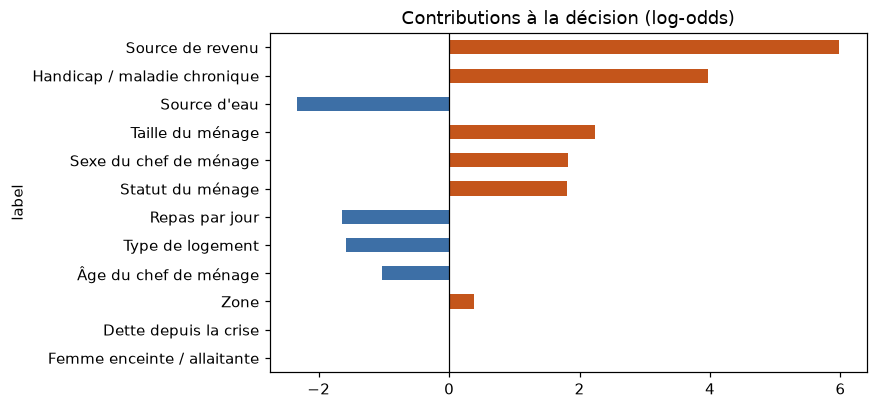

In [11]:
from training.train import main as train_main
meta = train_main([])  # entraîne et écrit eligibilite_api/model/model.joblib + metadata.json
from app.ml import load_model
load_model.cache_clear()
m = load_model()
menage = X_te.iloc[int(np.argmin(np.abs(p_te - thr)))].to_dict()  # le ménage le plus proche du seuil
r = m.predict(menage)
print(r["summary"]); print(f"score {r['score']:.2f} / seuil {r['threshold']:.2f} — à vérifier : {r['a_verifier']}")
ex = pd.DataFrame(r["explanation"]).set_index("label")
ex["contribution"].iloc[::-1].plot.barh(color=["#c4551b" if v > 0 else "#3d6fa6" for v in ex["contribution"].iloc[::-1]], figsize=(7, 4))
plt.axvline(0, c="k", lw=.8); plt.title("Contributions à la décision (log-odds)"); plt.show()

## 11. Importance globale des critères

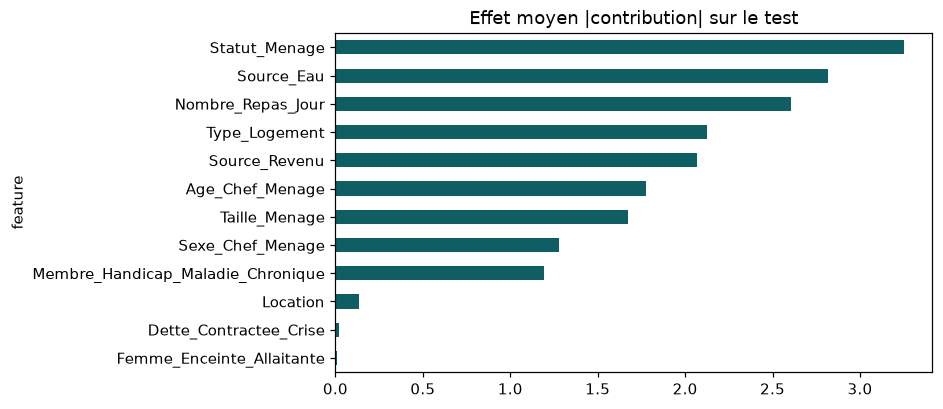

In [12]:
imp = pd.DataFrame(meta["importance_globale"]).set_index("feature")["importance"]
imp.iloc[::-1].plot.barh(color="#0f5e63", figsize=(7, 4)); plt.title("Effet moyen |contribution| sur le test"); plt.show()

## Conclusion

- **Rappel : 87 % (v2) → 98,5 %**, soit environ 9 fois moins de ménages éligibles exclus, avec une PR-AUC identique ou meilleure.
- Le modèle atteint le plafond théorique de ces données simulées ; les erreurs restantes se concentrent près du seuil.
  La **zone grise** (score à ±0,30 du seuil) regroupe environ 6 % des ménages mais environ 43 % des erreurs : ce sont eux que le dashboard fait revoir en priorité.
- Le modèle est déployé par l'API FastAPI de `eligibilite_api/`. Celle-ci reçoit les soumissions Kobo, explique chaque décision et permet à un humain de la confirmer ou de la désapprouver.
- **Prochaine étape** : les décisions modifiées par les humains (export CSV du dashboard) constituent de nouvelles étiquettes pour ré-entraîner le modèle sur des données réelles.